In [ ]:
import glob
import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests

NAMA = "Angelina Florensiana Jelita"
NIM = "2501010371"
EMAIL = "NIM@instiki.ac.id.com"

print("Library berhasil dipanggil!")
print("Waktu lokal:", datetime.now())
print("Pengambil:", NAMA, "-", NIM)

Library berhasil dipanggil!
Waktu lokal: 2026-11-11 07:10:39.397527
Pengambil: Angelina Florensiana Jelita - 2501010371


In [ ]:
URL = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": f"INSTIKI-BIFP243-Praktikum/1.0 ({EMAIL})"}

QUERY = """
[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;
"""

Path("docs").mkdir(parents=True, exist_ok=True)
Path("docs/query_overpass.txt").write_text(QUERY.strip(), encoding="utf-8")
print("Query final disimpan di docs/query_overpass.txt:\n")
print(Path("docs/query_overpass.txt").read_text(encoding="utf-8"))

Query final disimpan di docs/query_overpass.txt:

[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;


In [ ]:
def ambil_overpass(query, maks_percobaan=4, jeda=5):
    for percobaan in range(1, maks_percobaan + 1):
        try:
            r = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            print(f"[percobaan {percobaan}] status {r.status_code}, tunggu {jeda}s")
        except (requests.Timeout, requests.ConnectionError) as e:
            print(f"[percobaan {percobaan}] {type(e).__name__}, tunggu {jeda}s")
        time.sleep(jeda)
        jeda *= 2
    raise RuntimeError("Gagal mengambil data dari Overpass")

data = ambil_overpass(QUERY)
waktu_akuisisi = datetime.now(timezone.utc)
stamp = waktu_akuisisi.strftime("%Y%m%d_%H%M%S")

Path("data/raw").mkdir(parents=True, exist_ok=True)
raw_path = Path(f"data/raw/osm_akomodasi_kintamani_{stamp}.json")
raw_path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

print("Berkas mentah:", raw_path)
print("Jumlah elemen:", len(data["elements"]))

Berkas mentah: data/raw/osm_akomodasi_kintamani_20261111_071145.json
Jumlah elemen: 32


In [ ]:
hash_md5 = hashlib.md5(raw_path.read_bytes()).hexdigest()

provenance = {
    "url_endpoint": URL,
    "query": QUERY.strip(),
    "waktu_akuisisi_utc": waktu_akuisisi.isoformat(),
    "jumlah_elemen": len(data["elements"]),
    "nama_file_mentah": raw_path.name,
    "hash_md5": hash_md5,
    "lisensi": "Open Database License (ODbL)",
    "atribusi": "© OpenStreetMap contributors",
    "nama_pengambil": NAMA,
    "nim_pengambil": NIM,
}

Path("docs/provenance.json").write_text(
    json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")

print("Provenance berhasil dibuat: docs/provenance.json")
print(json.dumps({k: v for k, v in provenance.items() if k != "query"},
                 ensure_ascii=False, indent=2))

Provenance berhasil dibuat: docs/provenance.json
{
  "url_endpoint": "https://overpass-api.de/api/interpreter",
  "waktu_akuisisi_utc": "2026-11-11T07:11:45.282859+00:00",
  "jumlah_elemen": 32,
  "nama_file_mentah": "osm_akomodasi_kintamani_20261111_071145.json",
  "hash_md5": "feb160ac5fea040288c3ae483a2ef071",
  "lisensi": "Open Database License (ODbL)",
  "atribusi": "© OpenStreetMap contributors",
  "nama_pengambil": "Angelina Florensiana Jelita",
  "nim_pengambil": "2501010371"
}


In [ ]:
def ratakan(elements):
    baris = []
    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)   # node: lat/lon langsung; way/relation: di center
        baris.append({
            "osm_type": e["type"], "osm_id": e["id"],
            "nama": tg.get("name"), "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"), "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"), "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}",
        })
    return pd.DataFrame(baris)

akomodasi = ratakan(data["elements"])
print("Jumlah baris tabel:", len(akomodasi), "| jumlah elemen respons:", len(data["elements"]))
display(akomodasi.head())
print("\nJumlah per jenis:")
print(akomodasi["jenis"].value_counts(dropna=False))
print("\nTanpa nama:", akomodasi["nama"].isna().sum())

Jumlah baris tabel: 32 | jumlah elemen respons: 32


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696



Jumlah per jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Tanpa nama: 1


In [ ]:
duplikat = akomodasi.duplicated(subset=["osm_type", "osm_id"]).sum()
print("Duplikat (osm_type + osm_id):", duplikat)

tanpa_nama = akomodasi[akomodasi["nama"].isna()]
print("Akomodasi tanpa nama:", len(tanpa_nama))
display(tanpa_nama)

print("\nKoordinat kosong -> lat:", akomodasi["lat"].isna().sum(),
      "| lon:", akomodasi["lon"].isna().sum())
print("Rentang lat:", akomodasi["lat"].min(), "sampai", akomodasi["lat"].max())
print("Rentang lon:", akomodasi["lon"].min(), "sampai", akomodasi["lon"].max())

print("\nPersentase data kosong per kolom:")
print((akomodasi.isna().mean() * 100).round(2))

Duplikat (osm_type + osm_id): 0
Akomodasi tanpa nama: 1


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
31,way,1181397894,None,motel,-8.223372,115.254582,None,None,None,None,https://www.openstreetmap.org/way/1181397894



Koordinat kosong -> lat: 0 | lon: 0
Rentang lat: -8.2837958 sampai -8.2189435
Rentang lon: 115.2545822 sampai 115.4129261

Persentase data kosong per kolom:
osm_type          0.00
osm_id            0.00
nama              3.12
jenis             0.00
lat               0.00
lon               0.00
desa            100.00
bintang          96.88
jumlah_kamar     93.75
website          93.75
url_osm           0.00
dtype: float64


In [ ]:
Path("data/interim").mkdir(parents=True, exist_ok=True)
csv_path = Path("data/interim/akomodasi_kintamani.csv")
akomodasi.to_csv(csv_path, index=False, encoding="utf-8-sig")

print("Dataset CSV berhasil disimpan:", csv_path)
print("Jumlah baris:", len(akomodasi))
print("Jumlah kolom:", len(akomodasi.columns))
print("Kolom:", list(akomodasi.columns))

Dataset CSV berhasil disimpan: data/interim/akomodasi_kintamani.csv
Jumlah baris: 32
Jumlah kolom: 11
Kolom: ['osm_type', 'osm_id', 'nama', 'jenis', 'lat', 'lon', 'desa', 'bintang', 'jumlah_kamar', 'website', 'url_osm']


In [ ]:
from shapely.geometry import Point, LineString
from shapely.ops import unary_union, polygonize

QUERY_BATAS = """
[out:json][timeout:90];
relation["boundary"="administrative"]["name"="Kintamani"]["admin_level"="6"];
out geom;
"""
batas = ambil_overpass(QUERY_BATAS)
print("Jumlah batas wilayah ditemukan:", len(batas["elements"]))
rel = batas["elements"][0]
print("ID relation:", rel["id"], "| nama:", rel["tags"].get("name"),
      "| admin_level:", rel["tags"].get("admin_level"))

garis = [
    LineString([(p["lon"], p["lat"]) for p in m["geometry"]])
    for m in rel["members"]
    if m["type"] == "way" and m.get("role") == "outer" and "geometry" in m
]
poligon_kintamani = unary_union(list(polygonize(unary_union(garis))))
print("Tipe poligon:", poligon_kintamani.geom_type, "| valid:", poligon_kintamani.is_valid)
print("Bounding box:", poligon_kintamani.bounds)

cek = akomodasi.copy()
cek["di_dalam"] = cek.apply(
    lambda r: None if pd.isna(r["lat"]) or pd.isna(r["lon"])
    else poligon_kintamani.covers(Point(r["lon"], r["lat"])), axis=1)

print("\nHasil cek koordinat:")
print(cek["di_dalam"].value_counts(dropna=False))
print("\nBaris yang di luar wilayah atau tanpa koordinat:")
display(cek[cek["di_dalam"] != True])

Jumlah batas wilayah ditemukan: 1
ID relation: 20447233 | nama: Kintamani | admin_level: 6
Tipe poligon: Polygon | valid: True
Bounding box: (115.2323202, -8.3571424, 115.4589828, -8.1417656)

Hasil cek koordinat:
di_dalam
True    32
Name: count, dtype: int64

Baris yang di luar wilayah atau tanpa koordinat:


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm,di_dalam


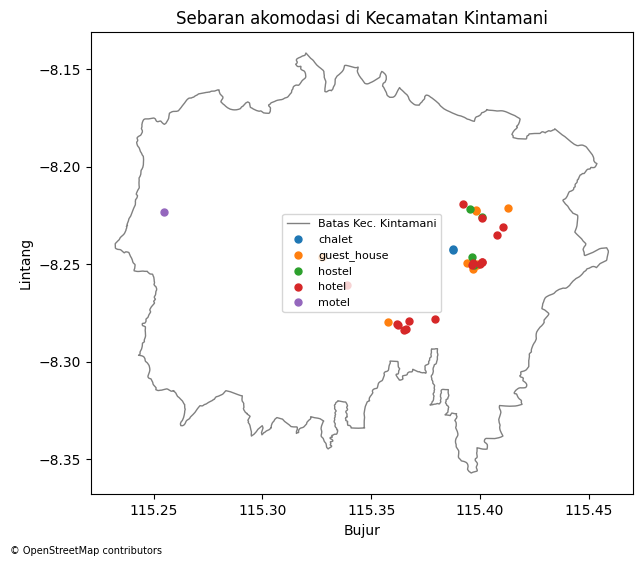

Peta disimpan: reports/peta_sebaran.png


In [ ]:
import matplotlib.pyplot as plt

Path("reports").mkdir(exist_ok=True)
bagian = [poligon_kintamani] if poligon_kintamani.geom_type == "Polygon" \
    else list(poligon_kintamani.geoms)

fig, ax = plt.subplots(figsize=(7, 6))
for i, poly in enumerate(bagian):
    x, y = poly.exterior.xy
    ax.plot(x, y, color="gray", linewidth=1,
            label="Batas Kec. Kintamani" if i == 0 else None)
for jenis, g in akomodasi.dropna(subset=["lat", "lon"]).groupby("jenis"):
    ax.scatter(g["lon"], g["lat"], s=25, label=jenis)
ax.set_xlabel("Bujur"); ax.set_ylabel("Lintang")
ax.set_title("Sebaran akomodasi di Kecamatan Kintamani")
ax.legend(fontsize=8)
fig.text(0.01, 0.01, "© OpenStreetMap contributors", fontsize=7)
fig.savefig("reports/peta_sebaran.png", dpi=150, bbox_inches="tight")
plt.show()
print("Peta disimpan: reports/peta_sebaran.png")

In [33]:
# Angka dan sumber BPS
TAHUN_DATA_BPS = 2023
JUMLAH_HOTEL_BPS = 19
JUMLAH_PENGINAPAN_BPS = 99
SUMBER_BPS = "https://banglikab.bps.go.id/id/publication/2024/09/26/3313f5ac27a3df4ff0ecbd03/kecamatan-kintamani-dalam-angka-2024.html"

jumlah_osm = len(akomodasi)
jumlah_bps = JUMLAH_HOTEL_BPS + JUMLAH_PENGINAPAN_BPS
persentase = round(jumlah_osm / jumlah_bps * 100, 2)

perbandingan_bps = pd.DataFrame([
    ["BPS", TAHUN_DATA_BPS, "Hotel", JUMLAH_HOTEL_BPS, SUMBER_BPS],
    ["BPS", TAHUN_DATA_BPS, "Penginapan", JUMLAH_PENGINAPAN_BPS, SUMBER_BPS],
    ["BPS", TAHUN_DATA_BPS, "Total", jumlah_bps, "Hotel + penginapan"],
    ["OpenStreetMap", waktu_akuisisi.year, "Akomodasi", jumlah_osm,
     "Hasil akuisisi melalui Overpass API"],
    ["Perbandingan", TAHUN_DATA_BPS, "Persentase kelengkapan (OSM / BPS x 100)", persentase,
     "Perkiraan kasar: kategori BPS dan tag OSM tidak sama persis, tahun data berbeda"],
], columns=["sumber", "tahun_data", "kategori", "jumlah", "keterangan"])

perbandingan_bps.to_csv("docs/perbandingan_bps.csv", index=False, encoding="utf-8-sig")
print("HASIL UJI KELENGKAPAN DATA")
print("Jumlah OSM:", jumlah_osm, "| Jumlah BPS:", jumlah_bps, "| Tahun BPS:", TAHUN_DATA_BPS)
print("Persentase kelengkapan:", persentase, "%")
display(perbandingan_bps)

HASIL UJI KELENGKAPAN DATA
Jumlah OSM: 32 | Jumlah BPS: 118 | Tahun BPS: 2023
Persentase kelengkapan: 27.12 %


,sumber,tahun_data,kategori,jumlah,keterangan
0,BPS,2023,Hotel,19.00,https://banglikab.bps.go.id/id/publication/202...
1,BPS,2023,Penginapan,99.00,https://banglikab.bps.go.id/id/publication/202...
2,BPS,2023,Total,118.00,Hotel + penginapan
3,OpenStreetMap,2026,Akomodasi,32.00,Hasil akuisisi melalui Overpass API
4,Perbandingan,2023,Persentase kelengkapan (OSM / BPS x 100),27.12,Perkiraan kasar: kategori BPS dan tag OSM tida...


In [38]:
sampel_10 = akomodasi.sample(n=10, random_state=42)
hasil_verifikasi = sampel_10[["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "url_osm"]].copy()

kolom_v = ["verifikasi_nama", "verifikasi_jenis", "verifikasi_lokasi", "sumber_verifikasi", "catatan"]
for k in kolom_v:
    hasil_verifikasi[k] = ""

# ===== ISI: hasil pemeriksaan nyata =====

# format -> osm_id: (nama, jenis, lokasi, sumber, catatan)
isian = {
    13068182153: ("Sesuai", "Sesuai", "sesuai", "https://www.openstreetmap.org/node/13068182153", ""),   # 1 Batur Sunrise Guesthouse
    6451134585:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/6451134585#map=19/-8.279139/115.367364", ""),   # 2 Caldera
    9769685089:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/9769685089#map=19/-8.222735/115.397971", ""),   # 3 Bunbulan Panorama Villas
    7058054537:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/7058054537#map=19/-8.278086/115.379134", ""),   # 4 Segara Hotel
    5065920543:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/5065920543#map=19/-8.283796/115.365242", ""),   # 5 The Volcania Guesthouse
    5175562421:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/5175562421#map=19/-8.222014/115.395349", ""),   # 6 Entrance to: Bunbulan Hill Hostel
    13284479326: ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/13284479326#map=19/-8.250311/115.396374", ""),   # 7 Lava Bali and Hot Spring
    9778735917:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/9778735917#map=19/-8.231158/115.410556", ""),   # 8 Villa Jempana
    5479746121:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/5479746121#map=19/-8.242693/115.387587", ""),   # 9 Hut
    1977779907:  ("Sesuai", "Sesuai", "Sesuai", "https://www.openstreetmap.org/node/1977779907#map=19/-8.283140/115.365844", ""),   # 10 The Lakeview Hotel Bali
}

for osm_id, nilai in isian.items():
    hasil_verifikasi.loc[hasil_verifikasi["osm_id"] == osm_id, kolom_v] = list(nilai)

Path("docs").mkdir(exist_ok=True)
hasil_verifikasi.to_csv("docs/verifikasi_10_sampel.csv", index=False, encoding="utf-8-sig")

terisi = (hasil_verifikasi["verifikasi_nama"] != "").sum()
print("Jumlah sampel:", len(hasil_verifikasi), "| sudah diverifikasi:", terisi)
if terisi < 10:
    print("PERHATIAN: verifikasi belum lengkap. Isi dictionary isian untuk semua sampel.")
display(hasil_verifikasi)

Jumlah sampel: 10 | sudah diverifikasi: 10


,osm_type,osm_id,nama,jenis,lat,lon,url_osm,verifikasi_nama,verifikasi_jenis,verifikasi_lokasi,sumber_verifikasi,catatan
29,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153,Sesuai,Sesuai,sesuai,https://www.openstreetmap.org/node/13068182153,
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/6451134585#...,
24,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/9769685089#...,
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/7058054537#...,
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/5065920543#...,
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/5175562421#...,
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/13284479326...,
25,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/9778735917#...,
12,node,5479746121,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/5479746121#...,
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907,Sesuai,Sesuai,Sesuai,https://www.openstreetmap.org/node/1977779907#...,


In [ ]:
N = len(akomodasi)
n_dup = int(duplikat)
n_nama = int(akomodasi["nama"].isna().sum())
n_koord = int(akomodasi["lat"].isna().sum())
n_luar = int((cek["di_dalam"] == False).sum())
n_desa = int(akomodasi["desa"].isna().sum())
n_bintang = int(akomodasi["bintang"].isna().sum())
n_kamar = int(akomodasi["jumlah_kamar"].isna().sum())

k_dup = ("Tidak ada duplikat berdasarkan osm_type + osm_id, jadi tidak ada baris yang dibuang."
         if n_dup == 0 else
         "Ada baris duplikat berdasarkan osm_type + osm_id. Baris kembar dibuang dan jumlahnya dicatat di laporan.")

k_nama = ("Semua akomodasi punya tag name. Tidak ada tindakan."
          if n_nama == 0 else
          "Baris tanpa nama dipertahankan karena objeknya tetap akomodasi yang valid (jenis dan koordinat ada) "
          "dan kolom nama boleh kosong. Nama tidak ditebak dari sumber lain; jumlahnya dilaporkan.")

k_koord = ("Semua baris punya koordinat: node memakai lat/lon langsung, bangunan memakai titik tengah (out center). "
           "Tidak ada tindakan."
           if n_koord == 0 else
           "Baris tanpa koordinat dipertahankan dan tidak diisi manual. Baris ini tidak tampil di peta "
           "dan tidak ikut pengecekan wilayah.")

k_luar = ("Semua titik berada di dalam batas Kecamatan Kintamani (admin_level=6) berdasarkan pengecekan "
          "titik-dalam-poligon. Tidak ada tindakan."
          if n_luar == 0 else
          "Titik di luar batas dipertahankan dan ditandai, tidak dibuang diam-diam, karena bisa berupa "
          "titik di tepi batas wilayah. Perlu dicek di peta OSM.")

k_desa = ("Tag addr:village tidak diisi pada semua baris, jadi ringkasan per desa tidak bisa disusun. "
          "Kolom dipertahankan (boleh kosong) dan tidak diisi dari sumber lain. Ini keterbatasan atribut OSM."
          if n_desa == N else
          "Sebagian baris tidak punya addr:village. Dipertahankan; ringkasan per desa hanya dari baris yang terisi.")

k_bintang = ("Kolom hampir selalu kosong. Dipertahankan bertipe teks sesuai ketentuan "
             "(konversi angka dilakukan di tahap cleaning) dan tidak dipakai untuk analisis.")
k_kamar = ("Dipertahankan bertipe teks sesuai ketentuan dan tidak diisi dari sumber lain. "
           "Karena banyak kosong, tidak dipakai untuk analisis.")

catatan = pd.DataFrame([
    ["Duplikat (osm_type + osm_id)", n_dup, k_dup],
    ["Nama kosong", n_nama, k_nama],
    ["Koordinat kosong", n_koord, k_koord],
    ["Di luar batas Kintamani", n_luar, k_luar],
    ["Kolom desa kosong", n_desa, k_desa],
    ["Kolom bintang kosong", n_bintang, k_bintang],
    ["Kolom jumlah_kamar kosong", n_kamar, k_kamar],
], columns=["masalah", "jumlah_baris", "keputusan"])

catatan.to_csv("docs/catatan_keputusan_kualitas.csv", index=False, encoding="utf-8-sig")
print("Catatan keputusan disimpan: docs/catatan_keputusan_kualitas.csv")
display(catatan)

Catatan keputusan disimpan: docs/catatan_keputusan_kualitas.csv


,masalah,jumlah_baris,keputusan
0,Duplikat (osm_type + osm_id),0,Tidak ada duplikat berdasarkan osm_type + osm_...
1,Nama kosong,1,Baris tanpa nama dipertahankan karena objeknya...
2,Koordinat kosong,0,Semua baris punya koordinat: node memakai lat/...
3,Di luar batas Kintamani,0,Semua titik berada di dalam batas Kecamatan Ki...
4,Kolom desa kosong,32,"Tag addr:village tidak diisi pada semua baris,..."
5,Kolom bintang kosong,31,Kolom hampir selalu kosong. Dipertahankan bert...
6,Kolom jumlah_kamar kosong,30,Dipertahankan bertipe teks sesuai ketentuan da...


In [ ]:
data_dictionary = pd.DataFrame([
    ["osm_type", "teks", "Jenis objek OSM: node, way, atau relation", "way", "Tidak"],
    ["osm_id", "bilangan bulat", "ID objek di OpenStreetMap", "123456789", "Tidak"],
    ["nama", "teks", "Nama akomodasi sesuai tag name", "(nama akomodasi)", "Ya, wajib dihitung jumlahnya"],
    ["jenis", "teks", "Nilai tag tourism", "guest_house", "Tidak"],
    ["lat", "desimal", "Lintang: koordinat titik atau titik tengah bangunan (WGS84)", "-8.27", "Tidak"],
    ["lon", "desimal", "Bujur: koordinat titik atau titik tengah bangunan (WGS84)", "115.37", "Tidak"],
    ["desa", "teks", "Desa sesuai tag addr:village", "(nama desa)", "Ya"],
    ["bintang", "teks", "Klasifikasi bintang (tag stars)", "3", "Ya"],
    ["jumlah_kamar", "teks", "Jumlah kamar (tag rooms)", "20", "Ya"],
    ["website", "teks", "Situs resmi akomodasi", "https://...", "Ya"],
    ["url_osm", "teks", "Tautan ke objek di openstreetmap.org untuk pengecekan",
     "https://www.openstreetmap.org/way/...", "Tidak"],
], columns=["kolom", "tipe", "deskripsi", "contoh", "boleh_kosong"])

data_dictionary.to_csv("docs/data_dictionary.csv", index=False, encoding="utf-8-sig")
print("Data dictionary berhasil disimpan!")
print("Kolom dataset sesuai dictionary:", list(akomodasi.columns) == data_dictionary["kolom"].tolist())
display(data_dictionary)

Data dictionary berhasil disimpan!
Kolom dataset sesuai dictionary: True


,kolom,tipe,deskripsi,contoh,boleh_kosong
0,osm_type,teks,"Jenis objek OSM: node, way, atau relation",way,Tidak
1,osm_id,bilangan bulat,ID objek di OpenStreetMap,123456789,Tidak
2,nama,teks,Nama akomodasi sesuai tag name,(nama akomodasi),"Ya, wajib dihitung jumlahnya"
3,jenis,teks,Nilai tag tourism,guest_house,Tidak
4,lat,desimal,Lintang: koordinat titik atau titik tengah ban...,-8.27,Tidak
5,lon,desimal,Bujur: koordinat titik atau titik tengah bangu...,115.37,Tidak
6,desa,teks,Desa sesuai tag addr:village,(nama desa),Ya
7,bintang,teks,Klasifikasi bintang (tag stars),3,Ya
8,jumlah_kamar,teks,Jumlah kamar (tag rooms),20,Ya
9,website,teks,Situs resmi akomodasi,https://...,Ya


In [ ]:

ATRIBUSI_SUDAH_DI_README_DAN_LAPORAN = True
JUMLAH_RUN_QUERY_UTAMA = 1

status_atribusi = "Ya" if ATRIBUSI_SUDAH_DI_README_DAN_LAPORAN else "Belum"

ethics_checklist = pd.DataFrame([
    ["Sumber data berasal dari OpenStreetMap melalui Overpass API", "Ya",
     "Endpoint tercatat di docs/provenance.json"],
    ["Pengambilan data dilakukan secara wajar", "Ya",
     f"Retry dengan jeda 5, 10, 20 detik; User-Agent dicantumkan; query utama dijalankan {JUMLAH_RUN_QUERY_UTAMA} kali"],
    ["Data kontak pribadi tidak diambil", "Ya",
     "Fungsi ratakan tidak memuat tag phone/email/media sosial; kolom dataset: " + ", ".join(akomodasi.columns)],
    ["Data mentah disimpan tanpa diubah", "Ya",
     f"Berkas {raw_path.name}; hash MD5 {hash_md5} tercatat di provenance.json"],
    ["Atribusi OpenStreetMap dicantumkan", status_atribusi,
     "© OpenStreetMap contributors di README dan laporan (isi nomor bagian/halaman bila sudah ada)"],
    ["Lisensi OpenStreetMap diperhatikan", "Ya", "ODbL, tercatat di provenance.json"],
    ["Sumber yang dilarang tidak digunakan", "Ya",
     "Hanya Overpass API dan data BPS; tidak ada scraping OTA atau halaman Google Maps"],
], columns=["pemeriksaan", "status", "bukti_keterangan"])

ethics_checklist.to_csv("docs/data_ethics_checklist.csv", index=False, encoding="utf-8-sig")
print("Data Ethics Checklist berhasil disimpan!")
display(ethics_checklist)

Data Ethics Checklist berhasil disimpan!


,pemeriksaan,status,bukti_keterangan
0,Sumber data berasal dari OpenStreetMap melalui...,Ya,Endpoint tercatat di docs/provenance.json
1,Pengambilan data dilakukan secara wajar,Ya,"Retry dengan jeda 5, 10, 20 detik; User-Agent ..."
2,Data kontak pribadi tidak diambil,Ya,Fungsi ratakan tidak memuat tag phone/email/me...
3,Data mentah disimpan tanpa diubah,Ya,Berkas osm_akomodasi_kintamani_20261111_071145...
4,Atribusi OpenStreetMap dicantumkan,Ya,© OpenStreetMap contributors di README dan lap...
5,Lisensi OpenStreetMap diperhatikan,Ya,"ODbL, tercatat di provenance.json"
6,Sumber yang dilarang tidak digunakan,Ya,Hanya Overpass API dan data BPS; tidak ada scr...


In [36]:
print("A. Jumlah seluruh data:", len(akomodasi))
print("\nB. Jumlah akomodasi per jenis")
print(akomodasi["jenis"].value_counts(dropna=False))
print("\nC. Jumlah akomodasi per desa (NaN = tag addr:village tidak diisi)")
print(akomodasi["desa"].value_counts(dropna=False))
print("\nD. Data kosong per kolom")
print(akomodasi.isna().sum())

A. Jumlah seluruh data: 32

B. Jumlah akomodasi per jenis
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

C. Jumlah akomodasi per desa (NaN = tag addr:village tidak diisi)
desa
None    32
Name: count, dtype: int64

D. Data kosong per kolom
osm_type         0
osm_id           0
nama             1
jenis            0
lat              0
lon              0
desa            32
bintang         31
jumlah_kamar    30
website         30
url_osm          0
dtype: int64


In [ ]:
file_wajib = [
    "data/interim/akomodasi_kintamani.csv",
    "docs/query_overpass.txt",
    "docs/provenance.json",
    "docs/data_dictionary.csv",
    "docs/data_ethics_checklist.csv",
    "docs/perbandingan_bps.csv",
    "docs/verifikasi_10_sampel.csv",
    "docs/catatan_keputusan_kualitas.csv",
    "reports/peta_sebaran.png",
]
print("PEMERIKSAAN KELENGKAPAN FILE PROYEK")
print("=" * 45)
raw = glob.glob("data/raw/osm_akomodasi_kintamani_*.json")
print("[OK]        " if len(raw) == 1 else "[CEK]       ", "data/raw:", raw)
for f in file_wajib:
    print("[OK]        " if Path(f).exists() else "[BELUM ADA] ", f)

print("\nPEMERIKSAAN BAGIAN YANG BELUM DIISI")
for f in glob.glob("docs/*.csv"):
    if "ISI" in Path(f).read_text(encoding="utf-8-sig"):
        print("[BELUM DIISI]", f)

prov = json.loads(Path("docs/provenance.json").read_text(encoding="utf-8"))
print("\nHash cocok dengan provenance:", hashlib.md5(Path(raw[0]).read_bytes()).hexdigest() == prov["hash_md5"])

PEMERIKSAAN KELENGKAPAN FILE PROYEK
[OK]         data/raw: ['data/raw/osm_akomodasi_kintamani_20261111_071145.json']
[OK]         data/interim/akomodasi_kintamani.csv
[OK]         docs/query_overpass.txt
[OK]         docs/provenance.json
[OK]         docs/data_dictionary.csv
[OK]         docs/data_ethics_checklist.csv
[OK]         docs/perbandingan_bps.csv
[OK]         docs/verifikasi_10_sampel.csv
[OK]         docs/catatan_keputusan_kualitas.csv
[OK]         reports/peta_sebaran.png

PEMERIKSAAN BAGIAN YANG BELUM DIISI

Hash cocok dengan provenance: True


In [37]:
import shutil
from pathlib import Path
from google.colab import files

REPO = Path("akomodasi_kintamani_2501010371")
shutil.rmtree(REPO, ignore_errors=True)
for sub in ["notebooks", "reports"]:
    (REPO / sub).mkdir(parents=True, exist_ok=True)
shutil.copytree("data", REPO / "data")
shutil.copytree("docs", REPO / "docs")
shutil.copy("reports/peta_sebaran.png", REPO / "reports")

shutil.make_archive(str(REPO), "zip", ".", str(REPO))
files.download(f"{REPO}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>